# Habits or Circumstances?
### Everyday routines, money behaviors, and background
**Shaden Alghamdi · EDA project**

**Main question:** What does this dataset reveal about everyday habits compared with financial behaviors and background factors among millionaire and non-millionaire profiles?

The Millionaire Habits Dataset contains 100,000 profiles with routines, income, saving, investing, education, and wealth status. Its 274 columns let us compare a familiar habits story with financial and background information. We use the full CSV and keep a focused table for the dashboard.

I chose it because the question is easy to relate to, and a weak habit result is still an answer worth reporting. I expect financial behaviors and background to add context, but the plots will decide what we can say.

**Source:** [DataSciKhan / Shair Khan on Kaggle](https://www.kaggle.com/datasets/datascikhan/millionaire-habits-dataset), v1.0.0. The profiles are synthetic; the findings describe this file and show associations, not causes or advice for becoming wealthy -sadly :( -.

## 1. The questions

| Question | What we compare |
|---|---|
| **Do everyday routines differ?** | Sleep, exercise, reading, focused work, and social media across wealth groups. |
| **What do money behaviors and background add?** | Savings, investing, and housing shares, followed by income, age, and education. |
| **Does the pattern remain with similar backgrounds?** | Both wealth groups inside the same broad age and income bands. |

Country is a filter. It is not a national wealth estimate. We leave network scores, mentor flags, and predictive models outside the final story so every main section answers one of these questions.

## 2. Setup
The analysis uses pandas, NumPy, matplotlib, and seaborn. The standard library setup below handles files and the initial download.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path
import urllib.request
import zipfile
import hashlib
import json

Path("data/raw").mkdir(parents=True, exist_ok=True)
Path("results/figures").mkdir(parents=True, exist_ok=True)
Path("dashboard").mkdir(exist_ok=True)
Path(".streamlit").mkdir(exist_ok=True)

### Shared colors, extra because I couldn't decide what theme to choose for the project
Edit `dashboard/theme.json` to change the palette. we will be using the same colors for plots and writes the Streamlit settings. The dashboard's canvas and surface colors can change without making notebook labels hard to read.

In [3]:
theme_path = Path("dashboard/theme.json")
THEME = {
    "primary": "#187366", "secondary": "#17324D", "accent": "#B78125",
    "negative": "#B04A5A", "background": "#F7F8F5", "text": "#17324D", "muted": "#66788A",
    "canvas": "#082938", "surface": "#163F4B", "light_text": "#F7F5EE",
    "light_muted": "#C6D8DB", "plot_background": "#F5F1E9"
}
if theme_path.exists():
    with open(theme_path) as file:
        THEME = json.load(file)
else:
    with open(theme_path, "w") as file:
        json.dump(THEME, file, indent=2)

GROUP_COLORS = {"Non-millionaire": THEME["secondary"], "Millionaire": THEME["primary"]}
HEATMAP_CMAP = sns.blend_palette([THEME["accent"], "white", THEME["primary"]], as_cmap=True)
sns.set_style("whitegrid")
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11,
    "axes.titleweight": "bold", "text.color": THEME["text"],
    "axes.labelcolor": THEME["text"], "xtick.color": THEME["text"],
    "ytick.color": THEME["text"], "axes.spines.top": False, "axes.spines.right": False})
config = ('[theme]\nbase = "dark"\n' + f'primaryColor = "{THEME["accent"]}"\n' +
    f'backgroundColor = "{THEME.get("canvas", "#082938")}"\n' +
    f'secondaryBackgroundColor = "{THEME.get("surface", "#163F4B")}"\n' +
    f'textColor = "{THEME.get("light_text", "#F7F5EE")}"\nfont = "sans serif"\n')
Path(".streamlit/config.toml").write_text(config)

154

## 3. Load and inspect the original file
The setup cell downloads the full public archive if the raw CSV is absent. We preserve literal `"None"` category labels and treat empty fields as missing; the default CSV reader would incorrectly erase those valid labels.

In [4]:
raw_folder = Path("data/raw")
csv_path = raw_folder / "Millionaire_Habits_Dataset.csv"
if not csv_path.exists():
    url = "https://www.kaggle.com/api/v1/datasets/download/datascikhan/millionaire-habits-dataset"
    zip_path = raw_folder / "kaggle_dataset.zip"
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path) as archive:
        for name in ["Millionaire_Habits_Dataset.csv", "Millionaire_Habits_Data_Dictionary.csv", "README.md", "validation_report.txt"]:
            archive.extract(name, raw_folder)

df = pd.read_csv(csv_path, keep_default_na=False, na_values=[""])
df.head()

,synthetic_person_id,dataset_version,generation_seed,country,region,urban_rural,age,age_group,gender,marital_status,dependents_count,education_level,highest_degree,field_of_study,education_years,financial_education_level,self_learning_hours_per_month,books_read_per_year,nonfiction_books_per_year,business_books_per_year,finance_books_per_year,online_courses_per_year,mentorship_access,employment_status,occupation_category,industry,years_of_experience,career_changes_count,current_job_tenure_years,annual_salary,annual_bonus,other_income,total_annual_income,income_percentile,income_stability_score,job_satisfaction,career_satisfaction,remote_work_frequency,weekly_work_hours,leadership_role,...,financial_goal_count,short_term_goal_count,long_term_goal_count,financial_review_frequency,money_mindset_score,wealth_building_score,habit_tracking,habit_tracking_frequency,routine_consistency_score,saving_consistency_score,investment_consistency_score,exercise_consistency_score,sleep_consistency_score,learning_consistency_score,goal_consistency_score,budget_consistency_score,overall_habit_consistency_score,wealth_category,financial_independence_status,high_saver_status,high_investor_status,entrepreneur_status,high_financial_literacy,high_productivity,high_debt_risk,financial_stability_score,investment_rate,housing_cost_ratio,luxury_spending_ratio,financial_buffer_months,asset_diversification_score,income_diversification_score,passive_income_ratio,business_income_ratio,investment_income_ratio,work_to_leisure_ratio,learning_to_work_ratio,health_consistency_index,financial_discipline_index,wealth_building_index
0,SYN_00000001,1.0.0,20260914,Switzerland,Zurich,Rural,40,36-45,Male,Married,0,High School,High School,Business,11,61.5,61.5,11.0,5.0,0.0,0.0,4.0,1.0,Employed Full-time,Healthcare,Energy,18,2.0,0.1,157159.16,40409.93,8112.41,205681.50,77.6,67.4,57.0,57.8,Always,47.2,0.0,...,4,0,1,Monthly,30.9,23.8,0,Rarely,65.4,28.2,54.0,27.9,69.4,45.8,46.9,28.9,37.9,1m_to_2.5m,0,0,1,0,0,0,0,37.0,0.096,0.099,0.003,0.6,92.1,68.2,0.184,0.0,0.184,5.14,0.303,57.4,28.0,35.6
1,SYN_00000002,1.0.0,20260914,United States,Northeast,Urban,62,56-65,Male,Single,2,Bachelor,Bachelor,Business,16,82.4,13.8,10.0,4.0,1.0,0.0,NaN,1.0,Retired,Legal,Finance,40,0.0,4.8,350512.97,39712.68,NaN,390874.76,95.9,80.0,75.7,NaN,Always,47.1,0.0,...,3,2,3,Monthly,50.0,72.6,1,Monthly,69.6,63.2,92.2,51.5,50.0,76.9,47.6,78.0,71.5,1m_to_2.5m,0,1,1,0,1,0,0,78.9,0.079,0.119,0.037,3.5,71.9,58.3,0.156,0.0,0.156,3.53,0.068,51.9,69.9,67.8
2,SYN_00000003,1.0.0,20260914,Bangladesh,Rajshahi,Urban,37,36-45,Female,Divorced,2,High School,High School,Science,12,29.8,19.9,9.0,5.0,1.0,1.0,5.0,1.0,Retired,Business/Finance,Transportation,18,1.0,8.2,30443.62,7074.10,348.04,37865.76,7.3,82.8,75.1,100.0,Rarely,30.2,0.0,...,2,2,2,Weekly,65.5,38.0,0,Weekly,40.4,58.9,60.2,54.6,45.6,52.4,42.4,32.1,46.8,500k_to_1m,1,1,1,0,0,0,1,42.2,0.536,1.000,0.004,0.1,100.0,53.4,0.451,0.0,0.451,2.80,0.153,52.4,47.4,100.0
3,SYN_00000004,1.0.0,20260914,Ireland,Ulster,Urban,68,65+,Male,Single,1,Bachelor,Bachelor,Computer Science,16,55.5,20.1,12.0,8.0,1.0,0.0,3.0,0.0,Unemployed,Education,Retail,48,1.0,0.6,230050.62,30963.62,2977.60,263991.84,86.8,54.7,36.3,60.8,Sometimes,45.7,0.0,...,1,0,0,Quarterly,57.6,29.5,0,Never,43.9,40.1,31.7,40.3,44.1,71.6,61.3,23.9,51.0,2.5m_to_5m,0,0,1,0,0,0,0,39.2,0.089,0.048,0.009,0.2,60.8,66.6,0.454,0.0,0.454,2.13,0.102,32.3,40.4,47.8
4,SYN_00000005,1.0.0,20260914,India,Delhi,Suburban,52,46-55,Non-binary,Divorced,1,Master,Master,Social Sciences,17,73.3,11.7,17.0,7.0,0.0,1.0,2.0,1.0,Employed Full-time,Sales,Real Estate,30,3.0,2.1,85602.37,13755.72,7860.17,107218.25,45.2,66.4,64.6,93.9,Always,36.8,0.0,...,1,3,2,Quarterly,45.3,61.3,1,Rarely,35.7,63.5,47.7,71.0,31.1,31.2,40.4,44.1,42.0,5m_to_10m,1,1,1,0,1,0,0,67.7,0.000,0.091,0.002,1.7,59.1,50.1,1.000,0.0,1.000,5.14,0.074,55.0,49.4,45.9


In [5]:
df.shape

(100000, 274)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 274 entries, synthetic_person_id to wealth_building_index
dtypes: float64(180), int64(49), object(45)
memory usage: 209.0+ MB


In [7]:
df.describe()

,generation_seed,age,dependents_count,education_years,financial_education_level,self_learning_hours_per_month,books_read_per_year,nonfiction_books_per_year,business_books_per_year,finance_books_per_year,online_courses_per_year,mentorship_access,years_of_experience,career_changes_count,current_job_tenure_years,annual_salary,annual_bonus,other_income,total_annual_income,income_percentile,income_stability_score,job_satisfaction,career_satisfaction,weekly_work_hours,leadership_role,professional_network_score,business_owner,business_count,business_age_years,business_revenue,business_profit,business_profit_margin,employees_count,startup_experience,entrepreneurship_experience_years,side_business,side_business_income,passive_business_income,business_failure_count,business_risk_tolerance,...,investment_research_hours_per_month,insurance_coverage_score,retirement_planning_score,financial_goal_count,short_term_goal_count,long_term_goal_count,money_mindset_score,wealth_building_score,habit_tracking,routine_consistency_score,saving_consistency_score,investment_consistency_score,exercise_consistency_score,sleep_consistency_score,learning_consistency_score,goal_consistency_score,budget_consistency_score,overall_habit_consistency_score,financial_independence_status,high_saver_status,high_investor_status,entrepreneur_status,high_financial_literacy,high_productivity,high_debt_risk,financial_stability_score,investment_rate,housing_cost_ratio,luxury_spending_ratio,financial_buffer_months,asset_diversification_score,income_diversification_score,passive_income_ratio,business_income_ratio,investment_income_ratio,work_to_leisure_ratio,learning_to_work_ratio,health_consistency_index,financial_discipline_index,wealth_building_index
count,100000.0,100000.000000,100000.000000,100000.000000,100000.000000,95525.000000,95851.000000,96945.000000,96676.000000,95707.000000,97449.000000,97562.000000,100000.000000,96332.000000,100000.000000,1.000000e+05,90138.000000,92625.000000,1.000000e+05,100000.000000,95370.000000,95525.000000,95429.000000,100000.000000,97083.00000,94729.000000,100000.000000,100000.000000,100000.000000,9.023600e+04,94345.000000,92649.000000,88152.000000,100000.000000,100000.00000,100000.00000,100000.000000,100000.000000,88094.000000,100000.000000,...,92793.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,20260914.0,53.237810,1.200770,15.766650,59.194216,23.978451,10.003130,5.007654,0.742583,0.613571,2.996183,0.399654,30.386740,1.998391,3.964703,1.266401e+05,18978.632258,3014.426875,1.486647e+05,50.000496,66.867634,69.865443,77.740288,43.514139,0.25231,49.998712,0.151570,0.228730,0.759763,1.157893e+04,1670.548502,0.022620,0.695673,0.149140,1.06090,0.25046,2012.246466,1507.961417,0.499716,52.992812,...,4.999132,49.866466,36.013613,2.99891,2.006550,1.499840,50.050489,44.250472,0.450920,50.077411,50.05050,49.904190,50.029267,49.953306,50.03869,49.959422,50.125796,50.018920,0.173130,0.731290,0.873440,0.151570,0.128650,0.172380,0.154500,52.118782,0.099174,0.242265,0.007666,1.684185,71.442529,51.190201,0.318751,0.039410,0.303922,8.144973,0.134059,50.027226,47.667345,58.815968
std,0.0,13.840685,1.097695,2.856036,16.960049,13.848675,3.169908,2.328195,0.804165,0.720481,1.728322,0.489830,12.381058,1.411968,3.875918,9.773487e+04,20132.828763,3018.330590,1.133338e+05,28.867694,16.301120,15.390014,12.926070,8.779252,0.43434,16.023246,0.358605,0.720984,2.627818,5.943056e+04,11428.494176,0.078619,2.559859,0.356228,3.25139,0.43328,5329.957786,5927.159186,0.70648

In [8]:
df.isna().sum()

synthetic_person_id           0
dataset_version               0
generation_seed               0
country                       0
region                        0
                             ..
work_to_leisure_ratio         0
learning_to_work_ratio        0
health_consistency_index      0
financial_discipline_index    0
wealth_building_index         0
Length: 274, dtype: int64

In [ ]:
data_dictionary = pd.read_csv(raw_folder / "Millionaire_Habits_Data_Dictionary.csv", keep_default_na=False)
data_dictionary.head()

,column_name,data_type,description,category,allowed_range_or_values,missingness,derived_or_generated,formula_if_derived
0,synthetic_person_id,object,Synthetic variable: Synthetic Person Id,A. Identification/Meta,100000 unique values,0.00%,No,
1,dataset_version,object,Synthetic variable: Dataset Version,A. Identification/Meta,1.0.0,0.00%,No,
2,generation_seed,int64,Synthetic variable: Generation Seed,A. Identification/Meta,20260914.00 to 20260914.00,0.00%,No,
3,country,object,Synthetic variable: Country,A. Identification/Meta,25 unique values,0.00%,No,
4,region,object,Synthetic variable: Region,A. Identification/Meta,99 unique values,0.00%,No,


The original file has **100,000 rows and 274 columns**. With valid `"None"` labels preserved, **33 columns** contain missing values, matching the source validation report. Millionaire status means net worth of at least **$1 million USD**.

In [10]:
missing_summary = pd.DataFrame({"missing_count": df.isna().sum(), "missing_percent": df.isna().mean() * 100})
missing_summary.to_csv("results/full_missingness.csv")
missing_summary[missing_summary.missing_count > 0].sort_values("missing_count", ascending=False)

,missing_count,missing_percent
business_failure_count,11906,11.906
employees_count,11848,11.848
tax_planning_behavior,11447,11.447
high_interest_debt,11398,11.398
portfolio_review_frequency,9996,9.996
mortgage_payment,9944,9.944
annual_bonus,9862,9.862
business_revenue,9764,9.764
estate_planning_status,8181,8.181
annual_luxury_spending,7874,7.874


In [11]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df.synthetic_person_id.duplicated().sum())
print("Status definition mismatches:", ((df.net_worth >= 1000000).astype(int) != df.millionaire_status).sum())
print("Currency values:", df.currency.unique())
print("Columns with missing values:", df.isna().any().sum())
print("Missing cells:", df.isna().sum().sum())

Duplicate rows: 0
Duplicate IDs: 0
Status definition mismatches: 0
Currency values: ['USD']
Columns with missing values: 33
Missing cells: 212640


## 4. Cleaning decisions
- Keep the 14 source fields that answer the questions or support a filter. Wealth components and outcome-derived fields stay out of the comparison.
- Keep all profiles: no exact duplicates or duplicate IDs were found. Rename the person ID and trim text whitespace.
- Keep unknown reading values blank. Each comparison uses the values it needs, without inventing observations.
- Flag unusual incomes but retain them. Their size alone does not show an error. Negative saving rates can describe a deficit.

In [12]:
habits = ["sleep_duration_hours", "exercise_hours_per_week", "books_read_per_year",
          "deep_work_hours_per_day", "social_media_hours_per_day"]
financial_sources = ["savings_rate", "investment_rate", "housing_cost_ratio"]
background = ["age", "total_annual_income", "education_level", "country"]
selected_columns = ["synthetic_person_id", "millionaire_status"] + habits + financial_sources + background

df_clean = df[selected_columns].drop_duplicates().copy()
df_clean = df_clean.rename(columns={"synthetic_person_id": "person_id"})
text_columns = ["person_id", "country", "education_level"]
for column in text_columns:
    df_clean[column] = df_clean[column].str.strip()

numeric_columns = [column for column in df_clean.columns if column not in text_columns]
before = df_clean[numeric_columns].isna().sum().sum()
for column in numeric_columns:
    df_clean[column] = pd.to_numeric(df_clean[column], errors="coerce")
print("New numeric gaps:", df_clean[numeric_columns].isna().sum().sum() - before)

New numeric gaps: 0


In [13]:
quality_checks = pd.Series({
    "missing_status": df_clean.millionaire_status.isna().sum(),
    "invalid_status": (~df_clean.millionaire_status.isin([0, 1])).sum(),
    "duplicate_ids": df_clean.person_id.duplicated().sum(),
    "invalid_age": (~df_clean.age.between(20, 85)).sum(),
    "negative_income": (df_clean.total_annual_income < 0).sum(),
    "invalid_sleep": (~df_clean.sleep_duration_hours.between(3, 12)).sum(),
    "invalid_savings": (~df_clean.savings_rate.between(-0.2, 1)).sum(),
    "invalid_investment": (~df_clean.investment_rate.between(0, 1)).sum(),
    "invalid_housing_ratio": (~df_clean.housing_cost_ratio.between(0, 1)).sum()
})
quality_checks.to_csv("results/quality_checks.csv")
quality_checks

missing_status           0
invalid_status           0
duplicate_ids            0
invalid_age              0
negative_income          0
invalid_sleep            0
invalid_savings          0
invalid_investment       0
invalid_housing_ratio    0
dtype: int64

In [14]:
Q1 = df_clean.total_annual_income.quantile(0.25)
Q3 = df_clean.total_annual_income.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = (df_clean.total_annual_income < lower) | (df_clean.total_annual_income > upper)
print("Income IQR flags:", outliers.sum())
print("Rows removed for income extremes: 0")
print("Negative savings rates retained:", (df_clean.savings_rate < 0).sum())

Income IQR flags: 4508
Rows removed for income extremes: 0
Negative savings rates retained: 1113


### Readable units and fixed bands
Multiply income shares by 100 for percentage plots. In the dashboard, 31.7% saved is also shown as $31.70 saved from each $100 earned. The age bands are explicit. Income and savings quarters use the full file once, so filtering does not move their boundaries.

In [15]:
df_clean["status_label"] = df_clean.millionaire_status.map({0: "Non-millionaire", 1: "Millionaire"})
financial = ["savings_rate_percent", "investment_rate_percent", "housing_cost_percent"]
for source, display in zip(financial_sources, financial):
    df_clean[display] = df_clean[source] * 100

age_order = ["20–34", "35–49", "50–64", "65–85"]
quartile_order = ["Q1 lowest", "Q2", "Q3", "Q4 highest"]
education_order = ["High School", "Some College", "Bachelor", "Master", "PhD", "Professional"]
df_clean["age_band"] = pd.cut(df_clean.age, bins=[19, 34, 49, 64, 85], labels=age_order)

boundaries = []
for source, destination in [("total_annual_income", "income_quartile"), ("savings_rate", "savings_quartile")]:
    df_clean[destination], edges = pd.qcut(df_clean[source], 4, labels=quartile_order, retbins=True)
    for i, group in enumerate(quartile_order):
        boundaries.append({"Measure": source, "Group": group, "Lower": edges[i], "Upper": edges[i+1]})
pd.DataFrame(boundaries).to_csv("results/quartile_boundaries.csv", index=False)
df_clean.to_csv("dashboard/clean_data.csv", index=False)
print("Focused table:", df_clean.shape)
df_clean.isna().sum()[df_clean.isna().any()]

Focused table: (100000, 21)


books_read_per_year    4149
dtype: int64

The focused file has **21 columns**, including seven display/group fields, and retains all 100,000 profiles. Only reading is incomplete: **4,149 unknown values**. Negative savings can describe a deficit. The full raw file is unchanged.

In [16]:
audit = pd.DataFrame({"column": df.columns})
audit["included"] = audit.column.isin(selected_columns)
audit["reason"] = np.where(audit.included, "Needed for a research question or filter", "Outside the focused questions; not automatically defective")
audit.loc[audit.column.isin(["net_worth", "total_assets", "total_liabilities", "wealth_bracket", "wealth_category", "net_worth_percentile"]), "reason"] = "Defines wealth, reconstructs wealth, or directly labels the outcome"
audit.to_csv("results/column_audit.csv", index=False)
clean_missing = pd.DataFrame({"missing_count": df_clean.isna().sum(), "missing_percent": df_clean.isna().mean()*100})
clean_missing.to_csv("results/clean_missingness.csv")
provenance = {"source_url": "https://www.kaggle.com/datasets/datascikhan/millionaire-habits-dataset",
    "original_retrieved_date": "2026-10-25", "revision_checked_date": "2026-10-26",
    "dataset_version": str(df.dataset_version.iloc[0]), "generation_seed": int(df.generation_seed.iloc[0]),
    "rows": len(df), "columns": len(df.columns), "synthetic": True,
    "sha256": hashlib.sha256(csv_path.read_bytes()).hexdigest()}
with open("results/provenance.json", "w") as file:
    json.dump(provenance, file, indent=2)

## 5. Who is being compared?
The count plot gives the group sizes. The income plots show why a typical value can be more useful than an average here. We use **typical** to mean the median: the middle recorded value, with half the values on either side.

In [17]:
status_summary = df_clean.status_label.value_counts().to_frame("profiles")
status_summary["percent"] = status_summary.profiles / len(df_clean) * 100
status_summary.to_csv("results/status_summary.csv")
status_summary

,profiles,percent
status_label,,
Non-millionaire,57508,57.508
Millionaire,42492,42.492


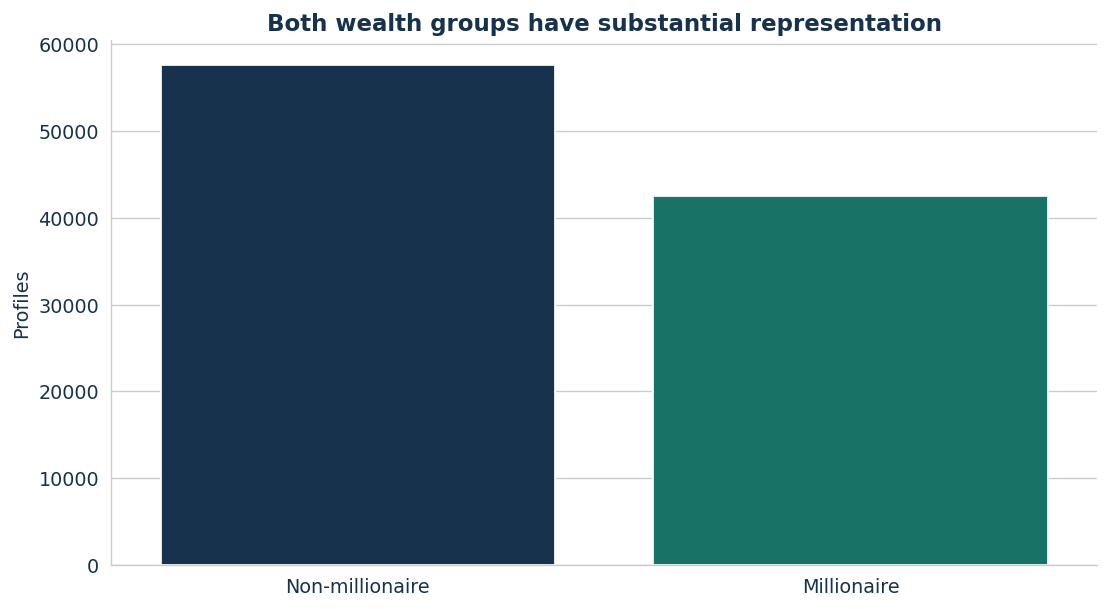

In [18]:
sns.countplot(data=df_clean, x="status_label", hue="status_label", order=list(GROUP_COLORS), palette=GROUP_COLORS, legend=False, saturation=1)
plt.title("Both wealth groups have substantial representation")
plt.xlabel("")
plt.ylabel("Profiles")
plt.tight_layout()
plt.savefig("results/figures/01_status_count.png", dpi=180)
plt.show()

Millionaire profiles make up **42.49%** of the file. Both groups are large enough for an overall comparison, though filtering can leave much smaller groups.

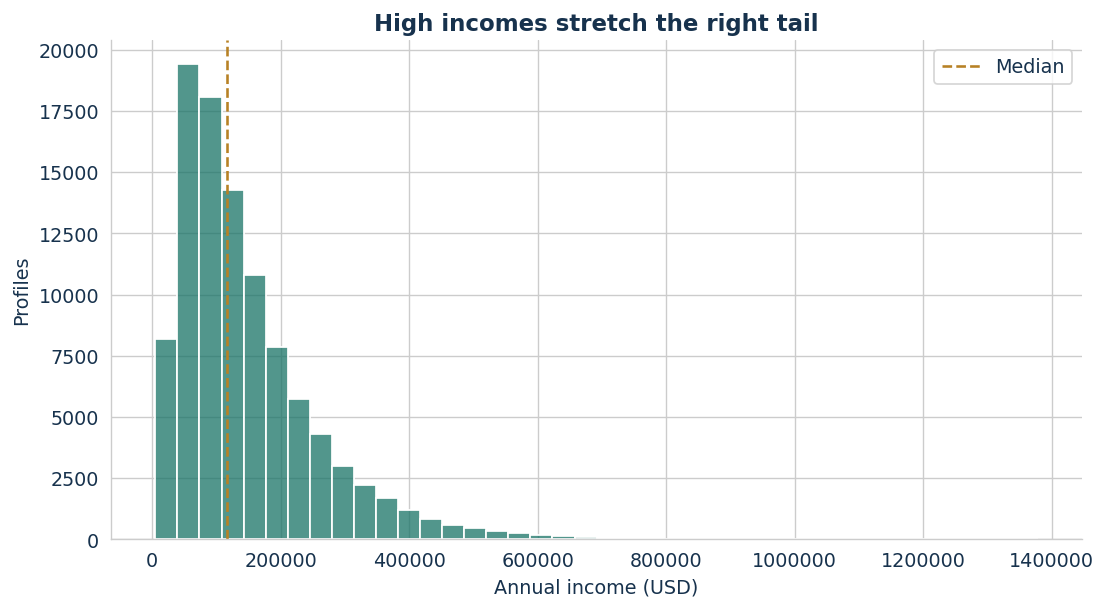

In [19]:
sns.histplot(data=df_clean, x="total_annual_income", bins=40, color=THEME["primary"])
plt.axvline(df_clean.total_annual_income.median(), color=THEME["accent"], linestyle="--", label="Median")
plt.title("High incomes stretch the right tail")
plt.xlabel("Annual income (USD)")
plt.ylabel("Profiles")
plt.ticklabel_format(style="plain", axis="x")
plt.legend()
plt.tight_layout()
plt.savefig("results/figures/02_income_histogram.png", dpi=180)
plt.show()

The average income is $148,665, above the $117,532 typical income. A smaller number of high incomes pulls the average upward. We keep those profiles and use a typical value when describing the middle of a group.

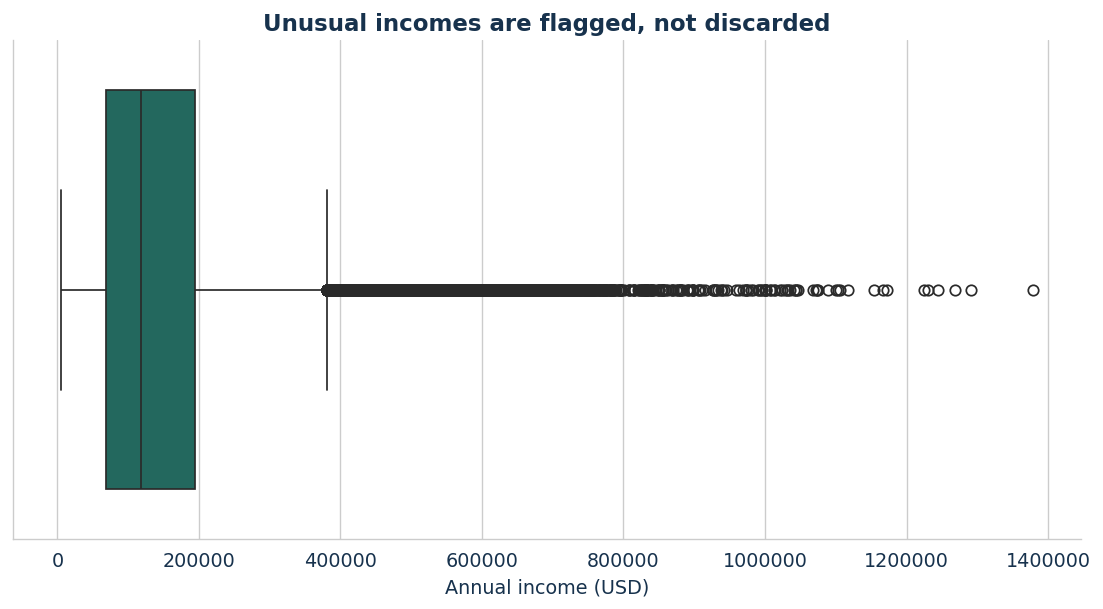

In [20]:
sns.boxplot(data=df_clean, x="total_annual_income", color=THEME["primary"])
plt.title("Unusual incomes are flagged, not discarded")
plt.xlabel("Annual income (USD)")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.savefig("results/figures/03_income_outliers.png", dpi=180)
plt.show()

The dots are values outside the boxplot. Their unusual size alone does not establish a recording error, so removing them would change the comparison without a sound reason.

## 6. Q1: Do everyday routines differ?
Each habit keeps its own units. We check typical values and how much the profiles vary, instead of turning a tiny difference into a strong claim.

In [21]:
habit_summary = df_clean.groupby("status_label")[habits].agg(["count", "mean", "median", "std"])
habit_summary.to_csv("results/habit_summary.csv")
habit_summary.round(3)

sleep_duration_hours                ... social_media_hours_per_day              
                               count   mean median  ...                       mean median    std
status_label                                        ...                                         
Millionaire                    42492  7.990    8.0  ...                      1.992    1.4  1.958
Non-millionaire                57508  7.986    8.0  ...                      1.998    1.4  1.967

[2 rows x 20 columns]

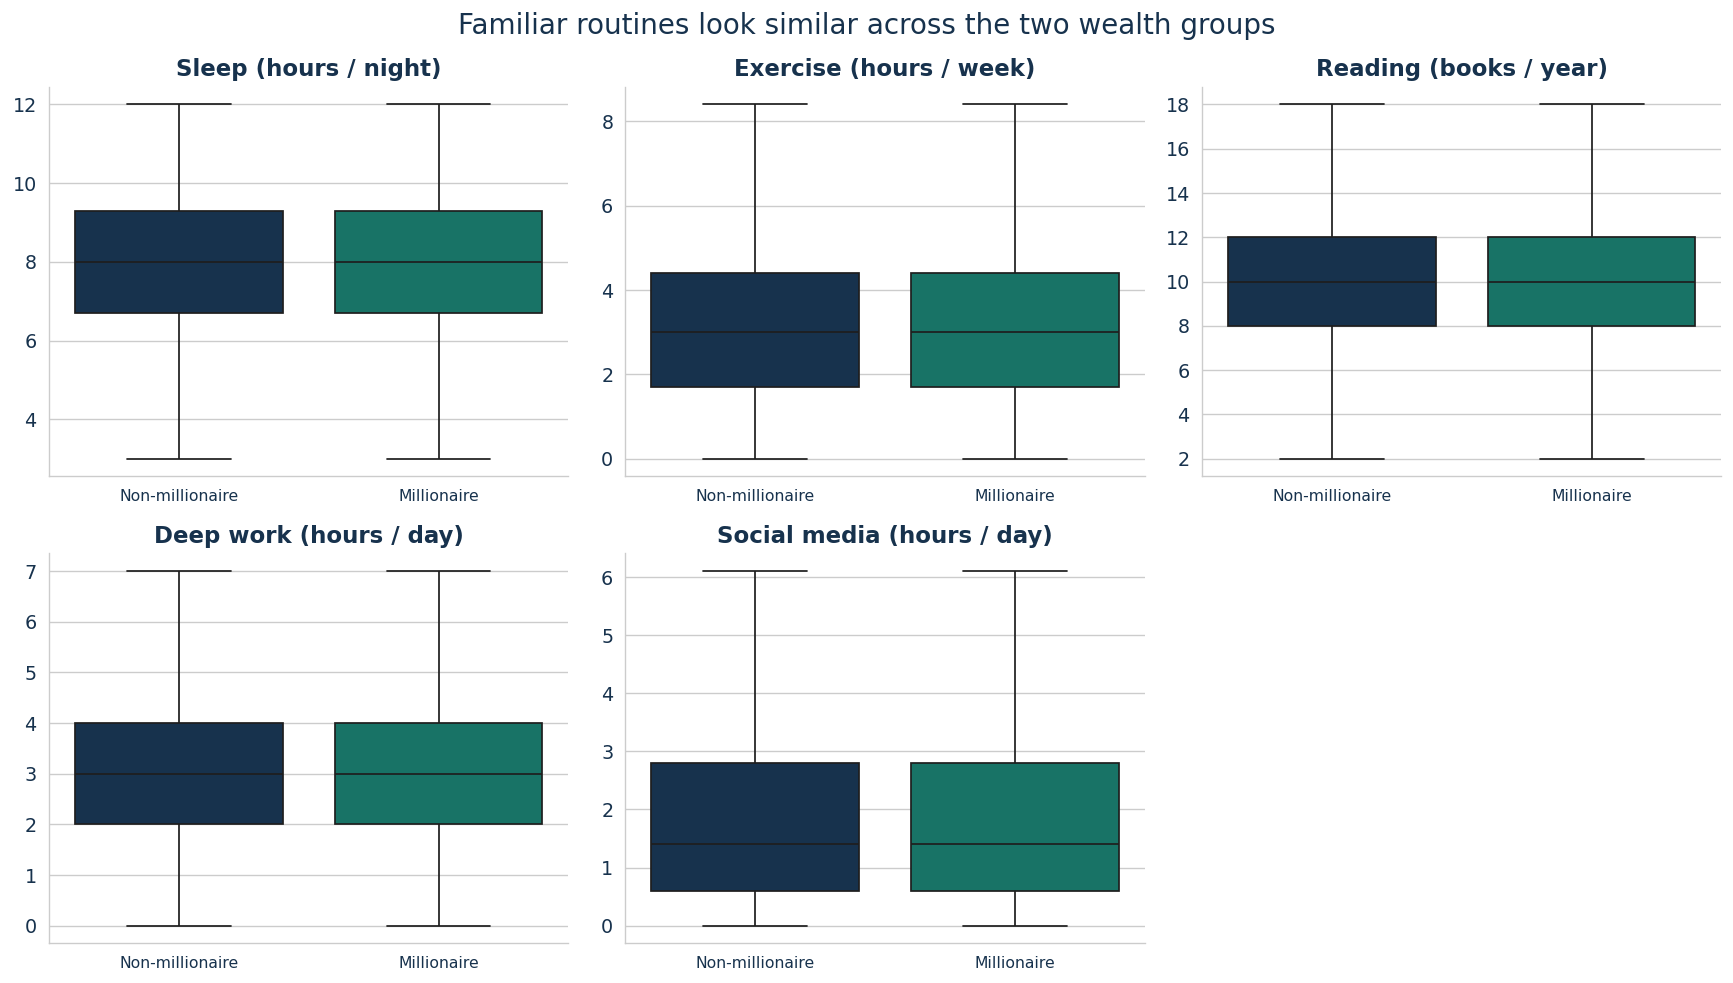

In [22]:
habit_names = ["Sleep (hours / night)", "Exercise (hours / week)", "Reading (books / year)",
               "Deep work (hours / day)", "Social media (hours / day)"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for column, name, ax in zip(habits, habit_names, axes.flat):
    sns.boxplot(data=df_clean, x="status_label", y=column, hue="status_label", order=list(GROUP_COLORS),
        palette=GROUP_COLORS, saturation=1, legend=False, showfliers=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelsize=9)
axes.flat[-1].axis("off")
fig.suptitle("Familiar routines look similar across the two wealth groups", fontsize=16, color=THEME["text"])
plt.tight_layout()
plt.savefig("results/figures/04_daily_routines.png", dpi=180)
plt.show()

The typical values match for all five routines: 8 hours of sleep, 3 hours of weekly exercise, 10 books a year, 3 hours of daily focused work, and 1.4 hours of daily social media. The boxes overlap closely too. These comparisons do not show a distinctive millionaire routine.

### A check on the size of a difference
For the dashboard's descriptive rule, we divide the difference in averages by the groups' pooled standard deviation. A magnitude below 0.20 counts as little average separation. This supporting calculation is not a significance test. We interpret comparisons only with 30 recorded values per wealth group.

In [23]:
measures = habits + financial + ["total_annual_income", "age"]
comparison_rows = []
for column in measures:
    a = df_clean.loc[df_clean.status_label == "Non-millionaire", column].dropna()
    b = df_clean.loc[df_clean.status_label == "Millionaire", column].dropna()
    pooled = np.sqrt(((len(a)-1)*a.var() + (len(b)-1)*b.var()) / (len(a)+len(b)-2))
    effect = (b.mean()-a.mean()) / pooled if pooled > 0 else 0
    comparison_rows.append({"column": column, "non_count": len(a), "millionaire_count": len(b),
        "non_median": a.median(), "millionaire_median": b.median(), "non_mean": a.mean(),
        "millionaire_mean": b.mean(), "gap": b.median()-a.median(), "effect": effect,
        "eligible": min(len(a), len(b)) >= 30})
comparison_summary = pd.DataFrame(comparison_rows)
comparison_summary.to_csv("results/comparison_summary.csv", index=False)
comparison_summary.round(3)

,column,non_count,millionaire_count,non_median,millionaire_median,non_mean,millionaire_mean,gap,effect,eligible
0,sleep_duration_hours,57508,42492,8.00,8.000,7.986,7.990,0.000,0.002,True
1,exercise_hours_per_week,57508,42492,3.00,3.000,3.080,3.062,0.000,-0.010,True
2,books_read_per_year,55161,40690,10.00,10.000,10.007,9.997,0.000,-0.003,True
3,deep_work_hours_per_day,57508,42492,3.00,3.000,3.012,3.027,0.000,0.010,True
4,social_media_hours_per_day,57508,42492,1.40,1.400,1.998,1.992,0.000,-0.003,True
5,savings_rate_percent,57508,42492,24.10,31.700,24.202,32.018,7.600,0.681,True
6,investment_rate_percent,57508,42492,6.60,10.700,8.747,11.501,4.100,0.261,True
7,housing_cost_percent,57508,42492,21.10,9.800,30.791,15.342,-11.300,-0.664,True
8,total_annual_income,57508,42492,84320.17,183103.835,101498.275,212498.877,98783.665,1.119,True
9,age,57508,42492,48.00,56.000,50.176,57.382,8.000,0.539,True


## 7. Q2: What do money behaviors and background add?
Savings, investment, and housing ratios describe shares of income. Income is money earned in a year, while millionaire status depends on accumulated net worth.

In [24]:
financial_summary = df_clean.groupby("status_label")[financial].agg(["count", "mean", "median"])
financial_summary.to_csv("results/financial_summary.csv")
financial_summary.round(2)

savings_rate_percent         ... housing_cost_percent       
                               count   mean  ...                 mean median
status_label                                 ...                            
Millionaire                    42492  32.02  ...                15.34    9.8
Non-millionaire                57508  24.20  ...                30.79   21.1

[2 rows x 9 columns]

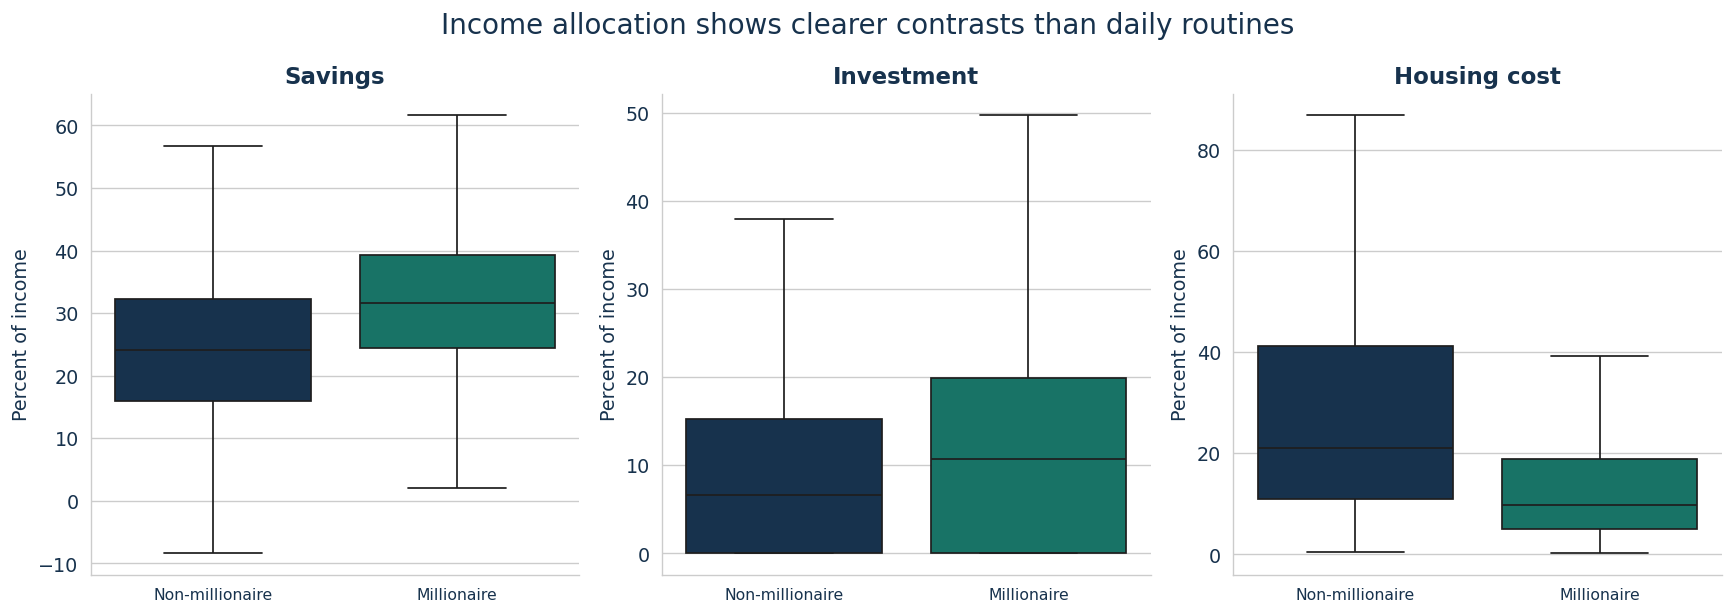

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for column, name, ax in zip(financial, ["Savings", "Investment", "Housing cost"], axes):
    sns.boxplot(data=df_clean, x="status_label", y=column, hue="status_label", order=list(GROUP_COLORS),
        palette=GROUP_COLORS, saturation=1, legend=False, showfliers=False, ax=ax)
    ax.set_title(name)
    ax.set_ylabel("Percent of income")
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=9)
fig.suptitle("Income allocation shows clearer contrasts than daily routines", fontsize=16)
plt.tight_layout()
plt.savefig("results/figures/05_financial_behaviors.png", dpi=180)
plt.show()

Millionaire profiles typically save 31.7% of income versus 24.1% for non-millionaires. That is $7.60 more saved from each $100 earned. The financial contrast is clearer than the routine comparisons.

A smaller housing share can also reflect a larger income, even without cheaper housing. Investment share describes contributions, not returns. The next comparisons help put these differences in context.

In [26]:
group_summaries = {}
for column, order in [("income_quartile", quartile_order), ("savings_quartile", quartile_order),
                      ("age_band", age_order), ("education_level", education_order)]:
    summary = df_clean.groupby(column, observed=True).millionaire_status.agg(profiles="size", share="mean").reindex(order)
    summary["millionaire_percent"] = summary.share * 100
    summary.to_csv("results/" + column + "_summary.csv")
    group_summaries[column] = summary

group_summaries["income_quartile"].round(2)

,profiles,share,millionaire_percent
income_quartile,,,
Q1 lowest,25000,0.11,10.93
Q2,25000,0.30,29.72
Q3,25000,0.51,50.84
Q4 highest,25000,0.78,78.48


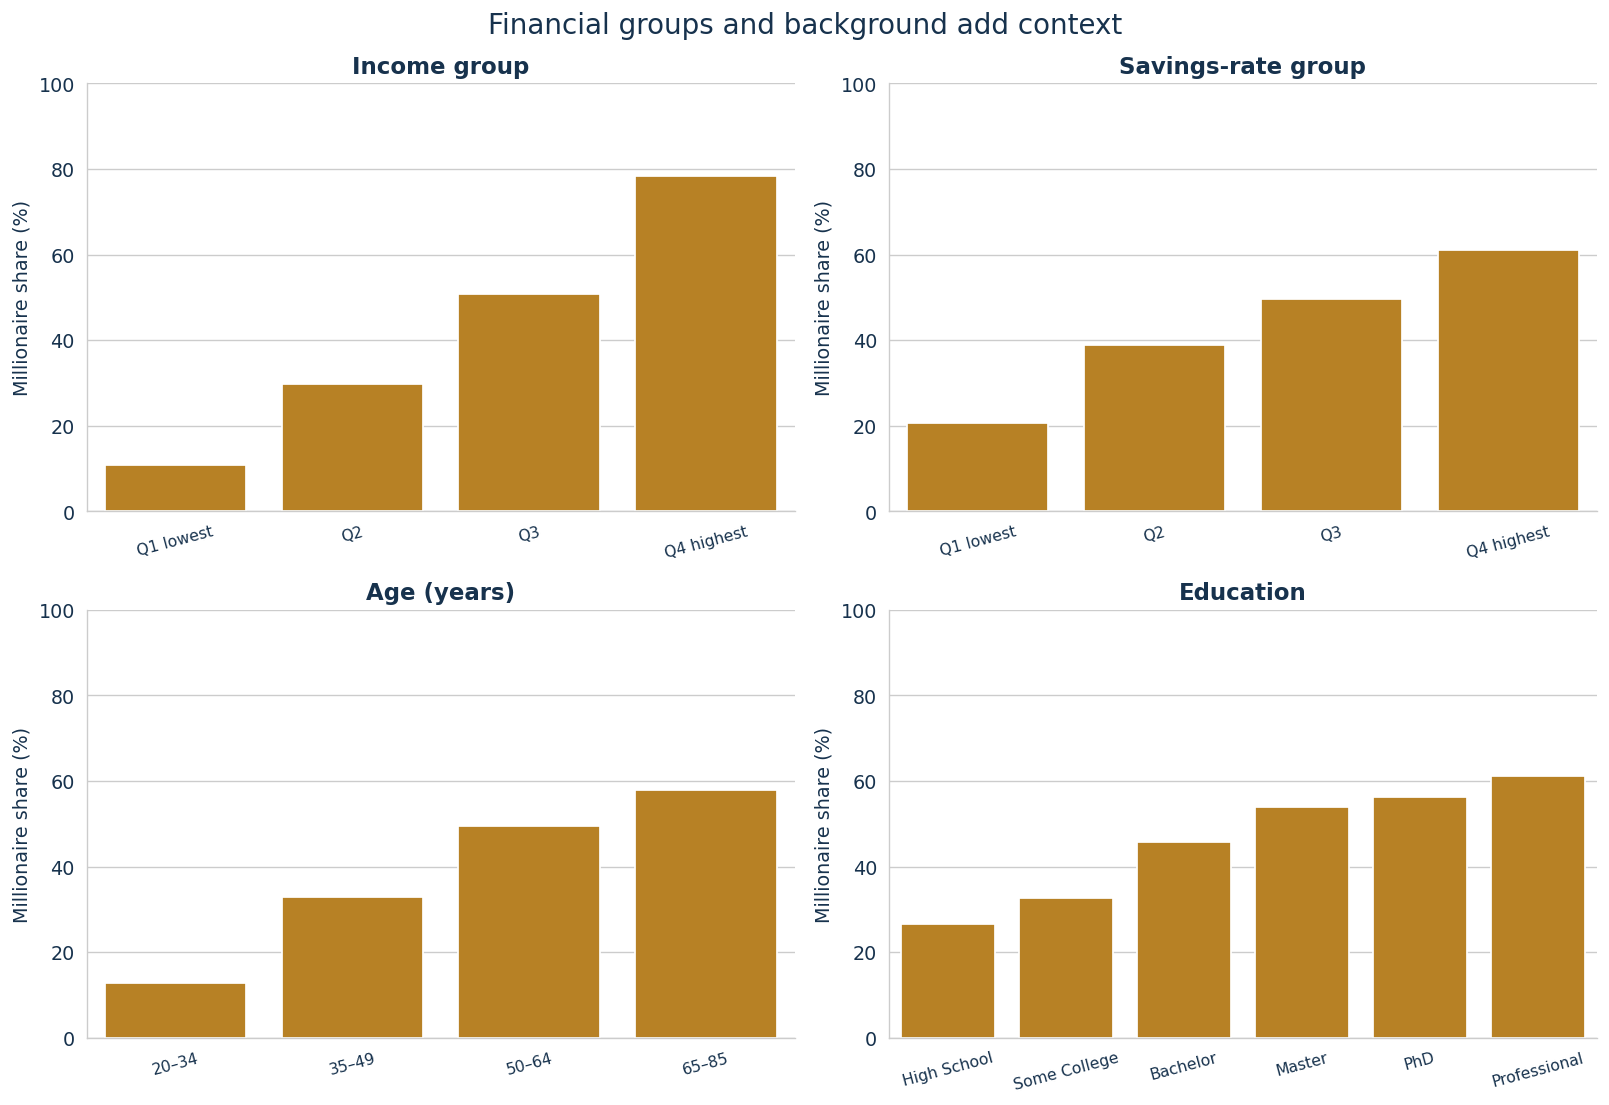

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for column, name, ax in zip(group_summaries, ["Income group", "Savings-rate group", "Age (years)", "Education"], axes.flat):
    summary = group_summaries[column].reset_index()
    sns.barplot(data=summary, x=column, y="millionaire_percent", color=THEME["accent"], saturation=1, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("")
    ax.set_ylabel("Millionaire share (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", labelsize=9, rotation=15)
fig.suptitle("Financial groups and background add context", fontsize=16)
plt.tight_layout()
plt.savefig("results/figures/06_group_comparisons.png", dpi=180)
plt.show()

The highest income quarter contains more millionaire profiles, but about 22 in every 100 profiles there are still non-millionaires. High earnings do not guarantee high accumulated wealth.

Age and education groups also have different wealth splits. Those groups differ in other ways, so these bars do not show what aging or gaining a qualification would cause.

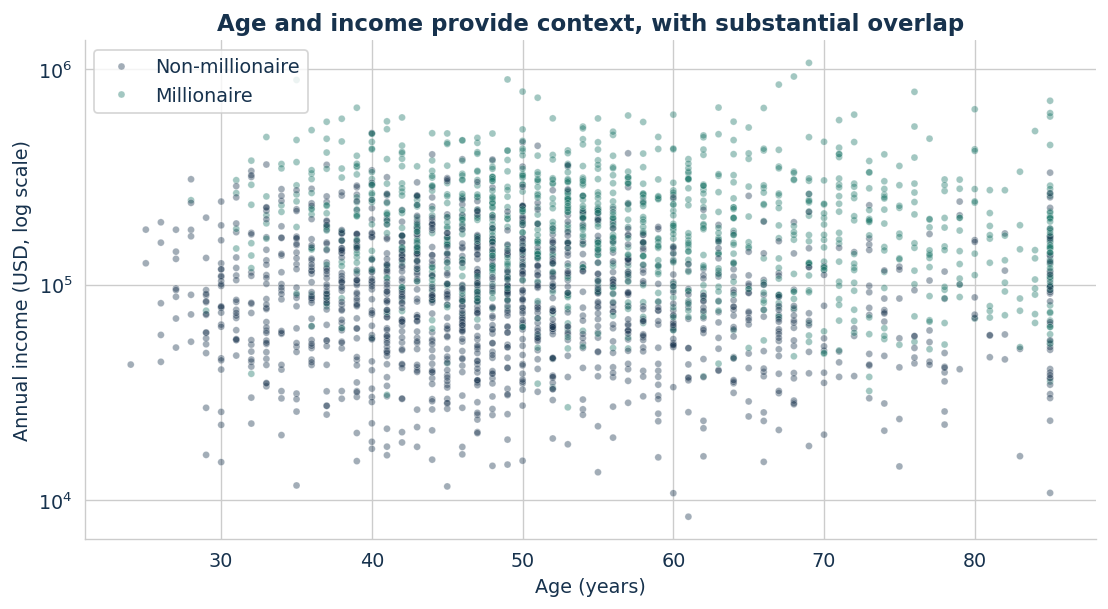

In [28]:
scatter_sample = df_clean.sample(n=2500, random_state=42)
sns.scatterplot(data=scatter_sample, x="age", y="total_annual_income", hue="status_label", palette=GROUP_COLORS, alpha=0.4, s=16)
plt.yscale("log")
plt.title("Age and income provide context, with substantial overlap")
plt.xlabel("Age (years)")
plt.ylabel("Annual income (USD, log scale)")
plt.legend(title="")
plt.tight_layout()
plt.savefig("results/figures/07_age_income.png", dpi=180)
plt.show()

Wealth groups overlap across the age–income view. The logarithmic income axis gives equal space to equal proportional changes, making the wide range readable. Only the drawing uses 2,500 sampled profiles; every summary uses the full available data.

### Correlation and feature selection
Correlation summarizes a linear relationship from -1 to +1. A value near zero does not rule out every relationship. We compare the focused numeric measures once, using only one of each fraction/percentage pair. Education stays categorical in the group chart.

In [29]:
correlation_columns = measures + ["millionaire_status"]
correlations = df_clean[correlation_columns].corr()
correlations.to_csv("results/correlations.csv")
target_correlations = correlations.millionaire_status.drop("millionaire_status").sort_values()
target_correlations.to_csv("results/target_correlations.csv")
target_correlations.round(3)

housing_cost_percent         -0.312
exercise_hours_per_week      -0.005
books_read_per_year          -0.002
social_media_hours_per_day   -0.001
sleep_duration_hours          0.001
deep_work_hours_per_day       0.005
investment_rate_percent       0.128
age                           0.257
savings_rate_percent          0.319
total_annual_income           0.484
Name: millionaire_status, dtype: float64

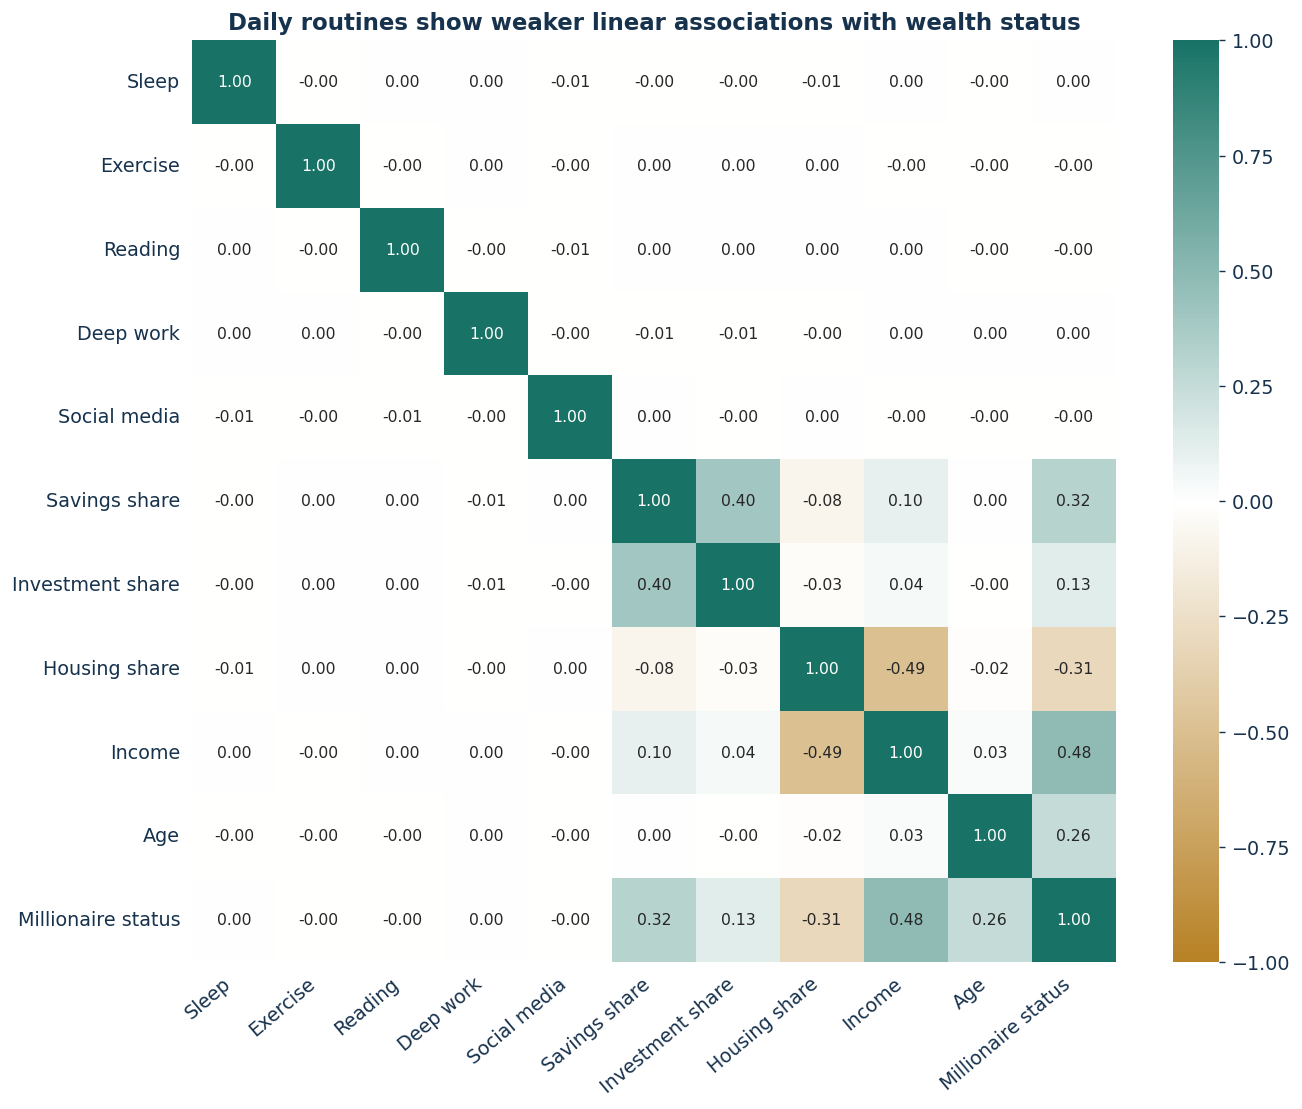

In [30]:
short_names = ["Sleep", "Exercise", "Reading", "Deep work", "Social media", "Savings share", "Investment share", "Housing share", "Income", "Age", "Millionaire status"]
plt.figure(figsize=(11, 9))
sns.heatmap(correlations, cmap=HEATMAP_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
    xticklabels=short_names, yticklabels=short_names, annot_kws={"size": 9})
plt.title("Daily routines show weaker linear associations with wealth status")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig("results/figures/08_correlation_heatmap.png", dpi=180)
plt.show()

Income, savings, housing share, and age have clearer linear links with status than the routines. The habit correlations are all below 0.006 in magnitude, which agrees with the overlapping boxes.

**Feature choices:** Keep the habits because their weak results answer Q1. Use income rather than its percentile and age rather than experience to avoid repeating information. Exclude net worth, assets, and outcome-derived labels because they define or reveal the wealth outcome. A low correlation alone is not a reason to delete a feature.

## 8. Q3: Does the pattern remain with similar backgrounds?
We compare the wealth groups inside 16 fixed age-and-income bands. Each comparison needs 30 recorded values per wealth group. This is a practical display rule, not exact matching or a guarantee of reliability.

In [31]:
context_rows = []
for (age, income), part in df_clean.groupby(["age_band", "income_quartile"], observed=True):
    for column in financial + habits:
        a = part.loc[part.status_label == "Non-millionaire", column].dropna()
        b = part.loc[part.status_label == "Millionaire", column].dropna()
        eligible = min(len(a), len(b)) >= 30
        effect = np.nan
        if eligible:
            pooled = np.sqrt(((len(a)-1)*a.var() + (len(b)-1)*b.var()) / (len(a)+len(b)-2))
            effect = (b.mean()-a.mean()) / pooled if pooled > 0 else 0
        context_rows.append({"age_band": str(age), "income_quartile": str(income), "column": column,
            "records": len(part), "non_count": len(a), "millionaire_count": len(b),
            "non_median": a.median(), "millionaire_median": b.median(),
            "gap": b.median()-a.median(), "effect": effect, "eligible": eligible})
context_results = pd.DataFrame(context_rows)
context_results.to_csv("results/context_comparisons.csv", index=False)
context_results[context_results.column == "savings_rate_percent"].round(3)

,age_band,income_quartile,column,records,non_count,millionaire_count,non_median,millionaire_median,gap,effect,eligible
0,20–34,Q1 lowest,savings_rate_percent,2178,2166,12,25.20,32.80,7.60,NaN,False
8,20–34,Q2,savings_rate_percent,1810,1723,87,26.70,34.80,8.10,0.804,True
16,20–34,Q3,savings_rate_percent,1581,1331,250,26.90,35.80,8.90,0.747,True
24,20–34,Q4 highest,savings_rate_percent,1254,736,518,24.80,32.45,7.65,0.669,True
32,35–49,Q1 lowest,savings_rate_percent,9512,8994,518,24.95,35.10,10.15,0.840,True
40,35–49,Q2,savings_rate_percent,9394,7656,1738,25.50,33.50,8.00,0.720,True
48,35–49,Q3,savings_rate_percent,9272,5703,3569,24.60,33.10,8.50,0.781,True
56,35–49,Q4 highest,savings_rate_percent,8999,2630,6369,23.30,32.00,8.70,0.805,True
64,50–64,Q1 lowest,savings_rate_percent,8030,6982,1048,24.30,34.10,9.80,0.839,True
72,50–64,Q2,savings_rate_percent,8507,5490,3017,23.60,32.60,9.00,0.809,True


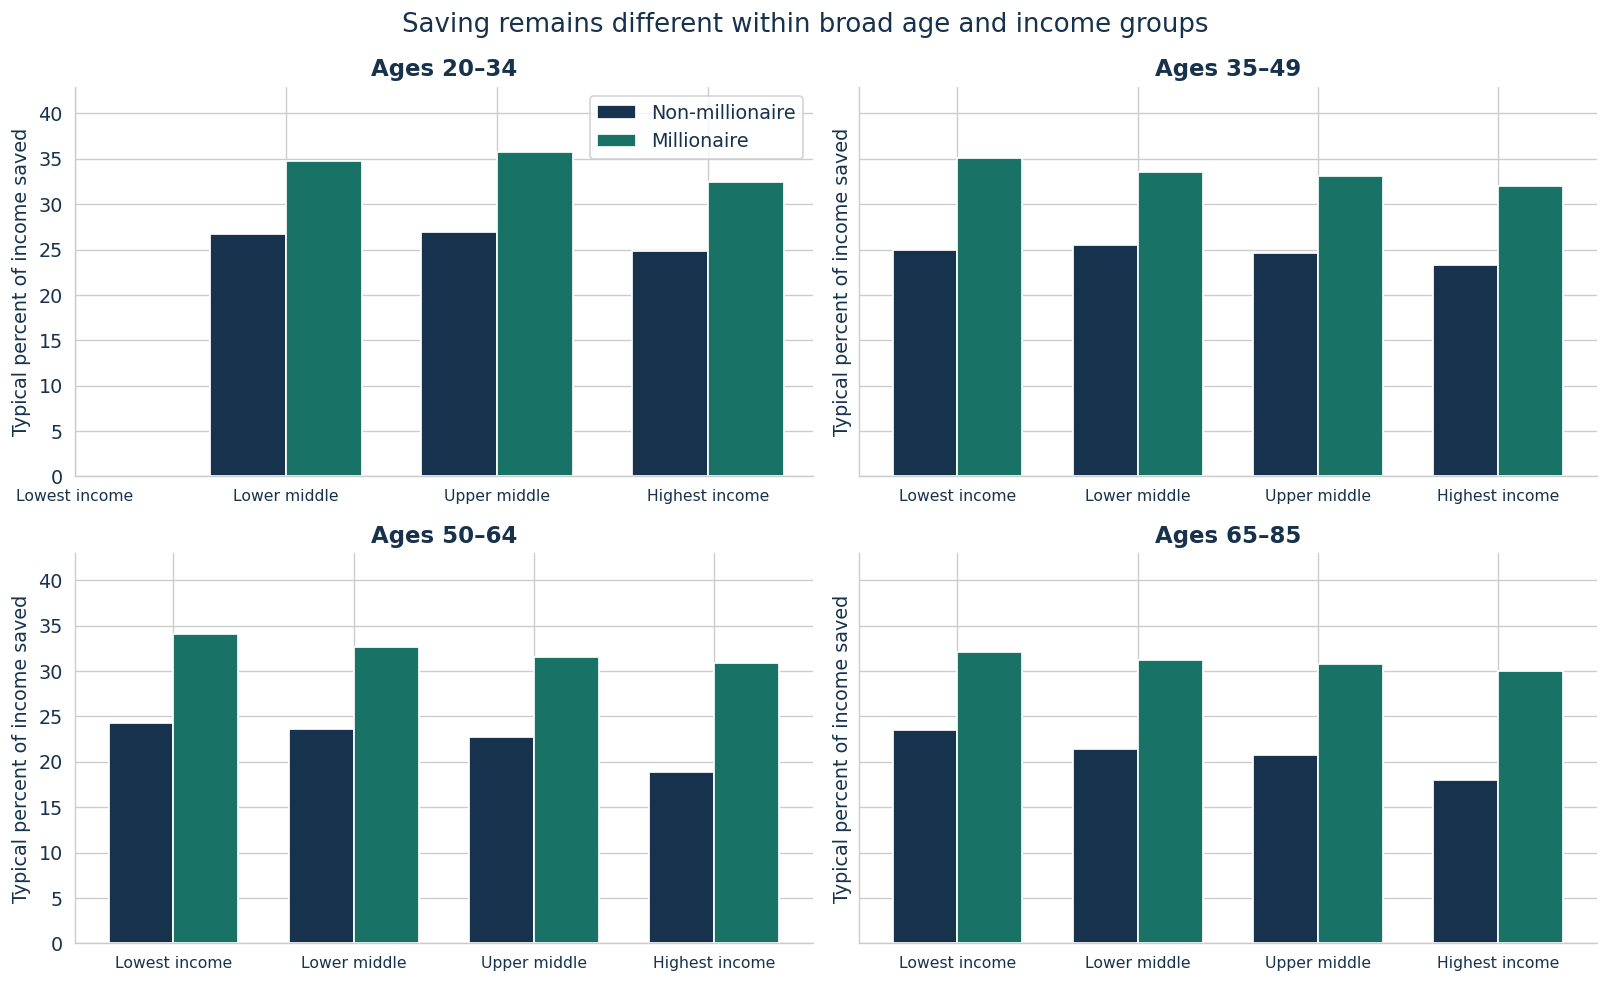

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
maximum = context_results.loc[context_results.column == "savings_rate_percent", ["non_median", "millionaire_median"]].max().max()
for age, ax in zip(age_order, axes.flat):
    table = context_results[(context_results.column == "savings_rate_percent") & (context_results.age_band == age)].copy()
    table = table.set_index("income_quartile").reindex(quartile_order)
    table.loc[~table.eligible, ["non_median", "millionaire_median"]] = np.nan
    positions = np.arange(4)
    ax.bar(positions - 0.18, table.non_median, width=0.36, color=THEME["secondary"], label="Non-millionaire")
    ax.bar(positions + 0.18, table.millionaire_median, width=0.36, color=THEME["primary"], label="Millionaire")
    ax.set_title("Ages " + age)
    ax.set_xticks(positions, ["Lowest income", "Lower middle", "Upper middle", "Highest income"])
    ax.set_ylabel("Typical percent of income saved")
    ax.set_ylim(0, maximum * 1.2)
    ax.tick_params(axis="x", labelsize=9)
axes.flat[0].legend()
fig.suptitle("Saving remains different within broad age and income groups", fontsize=15)
plt.tight_layout()
plt.savefig("results/figures/09_context_check.png", dpi=180)
plt.show()


The savings gap remains positive in all 15 bands with enough observations, covering 97.8% of profiles. It is therefore not only a difference between broad age and income groups. The youngest, lowest-income band has only 12 millionaire profiles, so it stays blank.

The bars show the actual typical savings rates for both groups. Broad bands still contain income differences and other background factors.

In [33]:
eligible_habits = context_results[context_results.column.isin(habits) & context_results.eligible].copy()
eligible_habits["little_separation"] = eligible_habits.effect.abs() < 0.20
within_habit_summary = eligible_habits.groupby("column").agg(
    eligible_cells=("eligible", "size"), cells_with_little_separation=("little_separation", "sum"),
    largest_absolute_mean_gap=("effect", lambda values: values.abs().max()))
within_habit_summary.to_csv("results/within_habit_summary.csv")
within_habit_summary.round(3)

,eligible_cells,cells_with_little_separation,largest_absolute_mean_gap
column,,,
books_read_per_year,15,15,0.065
deep_work_hours_per_day,15,15,0.134
exercise_hours_per_week,15,15,0.108
sleep_duration_hours,15,15,0.144
social_media_hours_per_day,15,15,0.088


All five routines still have small average differences in the 15 supported bands. The weak overall habit result is also visible when profiles share broad age and income ranges.

## 9. What we learned
1. **The routines look similar.** The five selected daily habits do not show a distinctive millionaire pattern in these comparisons.
2. **Money and background add context.** Saving, income, housing share, age, and education reveal clearer differences, with different meanings and limitations.
3. **The savings contrast remains within broad bands.** It does not disappear when we separate profiles by age and income.

**What I learned:** Check what a number measures, look at group sizes, and test an overall pattern with a closer comparison. A weak result is still useful when it answers the question.

**Limits and next steps:** The variables were measured together, so we cannot establish direction. Broad bands do not remove every difference between profiles. A future study could use documented survey data and follow people over time.

## 10. Dashboard 

The dashboard answers the same three questions. Filters update its summaries and takeaways. Main charts show actual typical values or millionaires per 100 profiles. Counts, distributions, and correlation details stay available below the main story.
